### 1. Data Ingestion & Initial Inspection

(FAZER DESCRICAO )

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

train ="../../../data/train.csv"
clientes = "../../../data/clientes.csv"
df = pd.read_csv(clientes)

code_cols = ["country_or_region", "commercial_region", "island", "municipality",
             "city", "postal_area", "postal_code", "street", "address"]

In [7]:
print("Dataset Dimention (Rows,Columns):", df.shape)

Dataset Dimention (Rows,Columns): (1143, 13)


In [8]:
df.head()

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


Gives the first five rows of the dataset<br>
After analysing the first five rows we can already see that we have some missing values(NaN)

---

### 1.1 Feature Overview & Data Types

 This line of code give us the total number of entries of the dataset as well as the total number of columns and their respective index and the data type(Dtype) of each column, we can also see the number of values which are not null for each variable(column).<br>


In [9]:
print("\n--- Datatype Information ---")
df.info()


--- Datatype Information ---
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          1143 non-null   int64  
 1   country_or_region    1143 non-null   str    
 2   commercial_region    1029 non-null   str    
 3   island               565 non-null    str    
 4   municipality         984 non-null    str    
 5   city                 597 non-null    str    
 6   postal_area          1072 non-null   str    
 7   postal_code          973 non-null    str    
 8   street               545 non-null    str    
 9   address              1137 non-null   str    
 10  customer_type        0 non-null      float64
 11  company_name         1143 non-null   str    
 12  customer_since_year  1143 non-null   int64  
dtypes: float64(1), int64(2), str(10)
memory usage: 116.2 KB


### 1.1.2 Numerical Variables:
**1.** **Customer_since_year**: By looking at the min and max values(they range between 2015-2026), we can see that the oldest client is from 2015 and the newest client is from 2026 respectively.
Note: Since the 2026 year is still going the number of costumers will probably still increase.<br>
**2.** **Customer_type**: The variable customer_type is empty (all the values are NaN, it doesn't contain any information), so it might be removed later.

 ### 1.1.3 Categorical Variables: 
**1.** **Customer_id**: Unique identifier of each customer (1143 unique values, no missing values and no duplicates). It is not a descriptive variable but the key used to join this table with train.csv/test.csv, so by itself it has no predictive meaning.<br>
**2.** **country_or_region**: This variable is highly unbalanced 94% of the values correspond to the same country/region(for example, CT10).<br>
**3.** **commercial_region:** *(37  unique categories)* is also concentrated, with RG17 covering 50% of the non-missing values. <br>
**4.** **island:** *(10 unique categories)* Appears only for 565 costumers,all from CT10, which suggests us that missing values could mean that the costumers are from mainland(might be better to create a new category named 'mainland') rather than an error recording the value. <br>
**5.** **municipality:** *(183 unique categories)* 159 missing values (13.9%). The most frequent municipality (MU1) has 58 customers, 65 municipalities have only one customer and the top 10 cover about 40% of the non-missing values.<br>
**6.** **city:** *(417 unique categories)* 546 missing values (47.8%), almost half of the customers. 360 cities appear only once (the most frequent one has only 14 customers), so the variable is very fragmented.<br>
**7.** **postal_area:** *(271 unique categories)* Only 71 missing values (6.2%), the most complete geographic variable after country_or_region. The most frequent area (PA259) has 57 customers and 126 areas appear only once.<br>
**8.** **postal_code:** *(828 unique categories)* 170 missing values (14.9%). 721 postal codes appear only once (maximum of 6 customers per code), so it behaves almost like an identifier.<br>
**9.** **street:** *(511 unique categories)* 598 missing values (52.3%), more than half of the customers. 485 streets appear only once (maximum of 5 customers per street).<br>
**10.** **adress:** *(1120 unique categories)* Only 6 missing values, and at most 3 customers share the same address. This means that there are few costumers per household(normally is only one buyer per household)<br>
**11.** **company_name:** No missing values and 1141 unique values for 1143 customers: only two names are repeated (Ltd 384 and Ltd 664, two customers each). <br>

**Note:** *postal_code, street, address and company_name are (almost) unique per customer, so they behave like identifiers and must be treated critically later (feature selection).*

**Note:**
*`customer_id` is excluded from the table because it is only an identifier; its uniqueness is checked in the Duplicates section.*

### 1.1.4 Cardinality
*Number of unique values per column compared with the number of customers, to identify identifier-like variables.*

In [10]:
# Unique values per column compared with the number of customers
cardinality = pd.DataFrame({
    "non_missing": df.notna().sum(),
    "n_unique": df.nunique(),
    "categories_with_one_customer": df.apply(lambda col: (col.value_counts() == 1).sum()),
    "max_customers_per_category": df.apply(lambda col: col.value_counts().max() if col.notna().any() else 0)
})
cardinality["unique_pct_of_non_missing"] = (cardinality["n_unique"] / cardinality["non_missing"] * 100).round(1)
cardinality.sort_values("unique_pct_of_non_missing", ascending=False)

,non_missing,n_unique,categories_with_one_customer,max_customers_per_category,unique_pct_of_non_missing
customer_id,1143,1143,1143,1,100.0
company_name,1143,1141,1139,2,99.8
address,1137,1120,1104,3,98.5
street,545,511,485,5,93.8
postal_code,973,828,721,6,85.1
city,597,417,360,14,69.8
postal_area,1072,271,126,57,25.3
municipality,984,183,65,58,18.6
commercial_region,1029,37,11,519,3.6
island,565,10,0,133,1.8


**1.** `customer_id` is unique for every customer (it is the join key). `company_name` (99.8%), `address` (98.5%), `street` (93.8%) and `postal_code` (85.1%) are almost unique, so they behave like identifiers and cannot be used as categories.<br>
**2.** `city`, `postal_area` and `municipality` have many categories with very few customers (e.g. 360 cities with only one customer), so rare categories will need to be grouped.<br>
**3.** `commercial_region` (37), `country_or_region` (11), `island` (10) and `customer_since_year` (12) have few categories and can be used directly, although `country_or_region` is dominated by CT10 (1079 customers).

---

### 1.2 Duplicates
*Repeated `customer_id` values and repeated `company_name` values.*

In [11]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated rows ignoring customer_id:", df.drop(columns="customer_id").duplicated().sum())
print("Duplicated customer_id:", df["customer_id"].duplicated().sum())
print("Duplicated company_name:", df["company_name"].duplicated().sum())
print("Duplicated address (non-missing):", df["address"].dropna().duplicated().sum())

Fully duplicated rows: 0
Duplicated rows ignoring customer_id: 0
Duplicated customer_id: 0
Duplicated company_name: 2
Duplicated address (non-missing): 17


In [12]:
# Customers that share the same company_name
df[df["company_name"].duplicated(keep=False)].sort_values("company_name")

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
390,255774,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,Municipality MU12: Council of Last Minute Edits,NaN,Postal area PA254: Hidden Sheet Sector,Postal code PC568: #REF! Delivery Route,NaN,Address AD414: Cell Without a Home,NaN,Excel Is Not A Database Ltd 384,2021
391,714679,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,Municipality MU12: Council of Last Minute Edits,NaN,Postal area PA254: Hidden Sheet Sector,Postal code PC568: #REF! Delivery Route,NaN,Address AD414: Cell Without a Home,NaN,Excel Is Not A Database Ltd 384,2017
998,652673,Country CT10: Land of The Final Version,Region RG33: We Will See Later,NaN,Municipality MU158: Council of Last Minute Edits,City CY378: Duplicate Row Moor,Postal area PA64: Hidden Sheet Sector,Postal code PC150: #REF! Delivery Route,Street ST427: Merged Cell Place,Address AD975: Cell Without a Home,NaN,Excel Is Not A Database Ltd 664,2015
999,821383,Country CT10: Land of The Final Version,NaN,NaN,NaN,NaN,Postal area PA64: Hidden Sheet Sector,Postal code PC150: #REF! Delivery Route,Street ST470: Relative Reference Rise,Address AD1047: Cell Without a Home,NaN,Excel Is Not A Database Ltd 664,2015


**1.** There are no duplicated rows or duplicated `customer_id` values, even when the id is ignored, so each row is a different customer.<br>
**2.** Two `company_name` values are repeated. The two "Ltd 384" customers share the same address but have different `customer_since_year` (2017 and 2021), so they may be the same company registered twice. The two "Ltd 664" customers have different addresses (possibly different branches). They are kept because they have different `customer_id` values.<br>
**3.** 17 `address` values are repeated, almost always by different companies, which suggests several businesses in the same building rather than duplicated customers.

---

### 1.3 Data Quality
*Check the completeness, uniqueness and consistency of the customer table before exploring it. The problems found here are only identified; they are handled in the pre-processing step.*

### 1.3.1 Missing Values
*Number and percentage of missing values per column.*

In [13]:
# Number and percentage of missing values per column
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1)
}).sort_values("n_missing", ascending=False)
missing

,n_missing,pct_missing
customer_type,1143,100.0
street,598,52.3
island,578,50.6
city,546,47.8
postal_code,170,14.9
municipality,159,13.9
commercial_region,114,10.0
postal_area,71,6.2
address,6,0.5
country_or_region,0,0.0


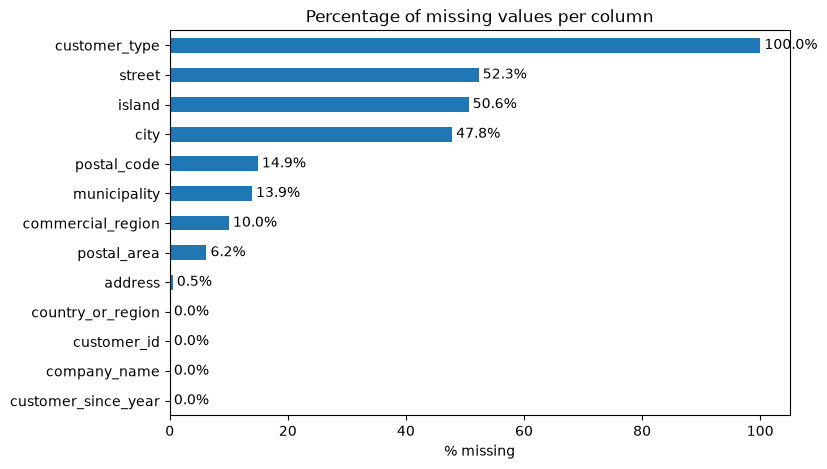

In [14]:
ax = missing["pct_missing"].plot(
    kind="barh",
    figsize=(8, 5),
    title="Percentage of missing values per column",
    xlabel="% missing"
)
plt.gca().invert_yaxis()

# Adiciona os valores com o símbolo "%" ao lado de cada barra
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

plt.show()

`customer_type` is completely empty (100%). `street` (52.3%), `island` (50.6%) and `city` (47.8%) are missing for about half of the customers, `postal_code`, `municipality` and `commercial_region` for 10–15%, while `customer_id`, `country_or_region`, `company_name` and `customer_since_year` are complete.<br>

**Note:** *Missing values do not always mean the same thing. In `island` they are structural (customers from the mainland). In `street` they show no regional pattern within CT10 (it seems to be an optional field left empty because `address` already holds the full address), but they are almost always missing for foreign customers. Since the missing values in `street` seem to be random, they carry little information about the customer.*

### 1.3.2 Structural Missing Values
*Check whether the missing values depend on other variables (e.g. `island` only filled for CT10 customers) or appear together in the same rows.*

In [15]:
# island filled vs missing per country_or_region
pd.crosstab(
    df["country_or_region"],
    df["island"].isna().map({False: "island filled", True: "island missing"}),
    margins=True
)

island,island filled,island missing,All
country_or_region,,,
Country CT10: Land of The Final Version,565,514,1079
Country CT11: Land of The Final Version,0,1,1
Country CT1: Land of The Final Version,0,1,1
Country CT2: Land of The Final Version,0,1,1
Country CT3: Land of The Final Version,0,1,1
Country CT4: Land of The Final Version,0,4,4
Country CT5: Land of The Final Version,0,49,49
Country CT6: Land of The Final Version,0,3,3
Country CT7: Land of The Final Version,0,2,2


In [16]:
# Percentage of missing values per column within each country_or_region
missing_cols = df.columns[df.isna().any()].drop("customer_type").to_list()
(df[missing_cols].isna().groupby(df["country_or_region"]).mean() * 100).round(1)

,commercial_region,island,municipality,city,postal_area,postal_code,street,address
country_or_region,,,,,,,,
Country CT10: Land of The Final Version,8.8,47.6,8.8,48.0,0.6,15.4,50.0,0.6
Country CT11: Land of The Final Version,0.0,100.0,100.0,0.0,100.0,0.0,100.0,0.0
Country CT1: Land of The Final Version,100.0,100.0,100.0,100.0,100.0,0.0,100.0,0.0
Country CT2: Land of The Final Version,0.0,100.0,100.0,0.0,100.0,0.0,100.0,0.0
Country CT3: Land of The Final Version,100.0,100.0,100.0,0.0,100.0,100.0,100.0,0.0
Country CT4: Land of The Final Version,100.0,100.0,100.0,50.0,100.0,75.0,100.0,0.0
Country CT5: Land of The Final Version,16.3,100.0,100.0,44.9,100.0,0.0,89.8,0.0
Country CT6: Land of The Final Version,33.3,100.0,100.0,0.0,100.0,0.0,66.7,0.0
Country CT7: Land of The Final Version,100.0,100.0,100.0,50.0,100.0,0.0,100.0,0.0


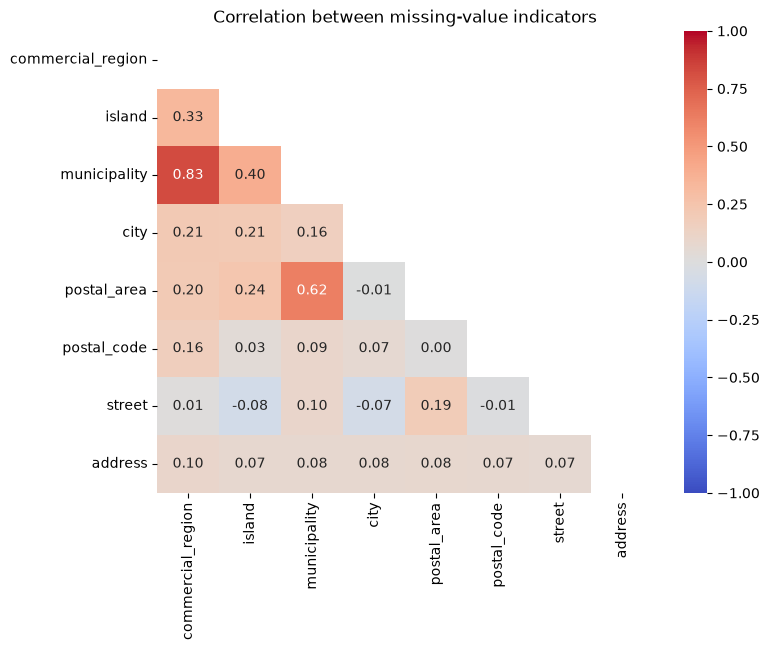

In [17]:
# Do the missing values appear together in the same rows? (correlation between missing-value indicators)
missing_corr = df[missing_cols].isna().astype(int).corr()
# Hide the upper triangle and the diagonal (the matrix is symmetric)
mask = np.triu(np.ones_like(missing_corr, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(missing_corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between missing-value indicators")
plt.show()

In [18]:
# Number of missing values per customer (customer_type excluded)
df[missing_cols].isna().sum(axis=1).value_counts().sort_index().rename_axis("n_missing_in_row").to_frame("n_customers")

,n_customers
n_missing_in_row,
0,121
1,388
2,338
3,135
4,72
5,58
6,24
7,5
8,2


**1.** `island` is only filled for CT10 customers: all 64 customers from other countries have no island, and within CT10 it is missing for 514 customers (probably from the mainland). These missing values are structural, not recording errors.<br>
**2.** For customers outside CT10, `island`, `municipality` and `postal_area` are always missing (and `street` almost always), so the detailed location was only recorded for CT10.<br>
**3.** In the heatmap, `commercial_region` and `municipality` (0.83) and `municipality` and `postal_area` (0.62) are usually missing together. For the remaining variables (`street`, `postal_code`, `city`, `address`) the missing values are almost independent (correlations close to 0).<br>
**4.** Only 121 customers (10.6%) have no missing values and most have 1 or 2. Removing rows with missing values would therefore lose almost the whole table.

---

### 1.4 Inconsistencies
*Empty variable (`customer_type`), wrong data types and plausible range of `customer_since_year`.*

In [19]:
# Data type of each column
df.dtypes.to_frame("dtype")

,dtype
customer_id,int64
country_or_region,str
commercial_region,str
island,str
municipality,str
city,str
postal_area,str
postal_code,str
street,str
address,str


In [20]:
# customer_since_year: range and values outside the plausible interval (2015 until the current year)
current_year = pd.Timestamp.today().year
print("Min:", df["customer_since_year"].min(), "| Max:", df["customer_since_year"].max())
print("Values outside [2015, current year]:", (~df["customer_since_year"].between(2015, current_year)).sum())

Min: 2015 | Max: 2026
Values outside [2015, current year]: 0


In [21]:
# customer_since_year vs the first purchase of the same customer in train.csv
train = pd.read_csv(train, usecols=["customer_id", "purchase_date"])
train["customer_id"] = train["customer_id"].astype(str)
first_purchase_year = pd.to_datetime(train["purchase_date"]).dt.year.groupby(train["customer_id"]).min().rename("first_purchase_year")

years = df.set_index("customer_id")[["customer_since_year"]].join(first_purchase_year, how="inner")
print("Customers present in train.csv:", len(years))
print("First purchase before customer_since_year:", (years["first_purchase_year"] < years["customer_since_year"]).sum())

Customers present in train.csv: 0
First purchase before customer_since_year: 0


In [34]:
# Text formatting: leading/trailing spaces and categories that only differ in upper/lower case
text_cols = df.select_dtypes(exclude="number").columns.drop("customer_id",errors="ignore")
pd.DataFrame({
    "leading_trailing_spaces": [(df[c].notna() & (df[c].str.strip() != df[c])).sum() for c in text_cols],
    "case_only_differences": [df[c].nunique() - df[c].str.strip().str.lower().nunique() for c in text_cols]
}, index=text_cols)

,leading_trailing_spaces,case_only_differences
country_or_region,0,0
commercial_region,0,0
island,0,0
municipality,0,0
city,0,0
postal_area,0,0
postal_code,0,0
street,0,0
address,0,0
company_name,0,0


### *Data Quality Conclusions*
*Summary of the problems found and how they will be handled later.*<br>

**1.** `customer_type` is empty and will be removed.<br>
**2.** The missing values in `island` and in the geographic variables of non-CT10 customers are structural, so they will be replaced by their own category (e.g. "mainland"/"foreign") instead of being imputed.<br>
**3.** `customer_id` is only used to join with train.csv/test.csv. `company_name`, `address`, `street` and `postal_code` behave like identifiers and will be excluded from modelling.<br>
**4.** `city`, `postal_area` and `municipality` have high cardinality, so rare categories will be grouped.<br>
**5.** There are no duplicated customers to remove, and `customer_since_year` is consistent with train.csv, although the 2015 value probably groups older customers.

---

### 1.5 Descriptive Statistics 

In [23]:
df.describe(include ="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1143.0,NaN,NaN,NaN,553917.786527,259693.430653,103940.0,323855.5,555330.0,782527.5,998870.0
country_or_region,1143,11,Country CT10: Land of The Final Version,1079,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commercial_region,1029,37,Region RG17: We Will See Later,519,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,565,10,Island IS7: The Pivot Archipelago,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
municipality,984,183,Municipality MU1: Council of Last Minute Edits,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,597,417,City CY194: PowerPoint New Hills,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
postal_area,1072,271,Postal area PA259: Hidden Sheet Sector,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
postal_code,973,828,Postal code PC545: #REF! Delivery Route,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street,545,511,Street ST192: Last Save Walk,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,1137,1120,Address AD489: Cell Without a Home,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


*After looking for the content in the table we can see that we have a lot of NaN values. This occurs because since is not possible for some columns to calculate their values due to their type being numerical and the value they calculate being ordinal and vice-versa .*<br>
So to solve this issue we did the code below:

In [24]:
# customer_id is an identifier, not a number, so it is stored as text
df["customer_id"] = df["customer_id"].astype(str)

# Numeric variables
display(df.describe().T)

# Categorical variables (customer_id excluded: it is only an identifier)
display(df.drop(columns="customer_id").describe(exclude="number").T)

,count,mean,std,min,25%,50%,75%,max
customer_type,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_since_year,1143.0,2016.999125,2.971405,2015.0,2015.0,2015.0,2018.0,2026.0


,count,unique,top,freq
country_or_region,1143,11,Country CT10: Land of The Final Version,1079
commercial_region,1029,37,Region RG17: We Will See Later,519
island,565,10,Island IS7: The Pivot Archipelago,133
municipality,984,183,Municipality MU1: Council of Last Minute Edits,58
city,597,417,City CY194: PowerPoint New Hills,14
postal_area,1072,271,Postal area PA259: Hidden Sheet Sector,57
postal_code,973,828,Postal code PC545: #REF! Delivery Route,6
street,545,511,Street ST192: Last Save Walk,5
address,1137,1120,Address AD489: Cell Without a Home,3
company_name,1143,1141,Excel Is Not A Database Ltd 384,2


After running the lines of code above, we can observe that the customer table contains 1143 customers and 13 variables . Each customer has one unique identifier(customer_id) so the table can be joined to the train.csv without duplicating rows.

**1.** `customer_type` is stored as float but has 0 values out of 1143, so it is an empty column. `customer_id` was converted to text because it is an identifier; the other columns have the expected data types.<br>
**2.** `customer_since_year` ranges from 2015 to 2026, so there are no impossible values. However, 664 customers (58%) are from 2015, which probably means "2015 or earlier" (the start of the records) rather than the real starting year.<br>
**3.** Of the 610 customers that appear in train.csv, none made a purchase before their `customer_since_year`, so both tables are consistent.<br>
**4.** No text column has leading/trailing spaces or categories that only differ in upper/lower case.

---

### 1.6 Univariate Analysis 

*Univariate analysis studies one variable at a time to understand its charateristics and distribution*

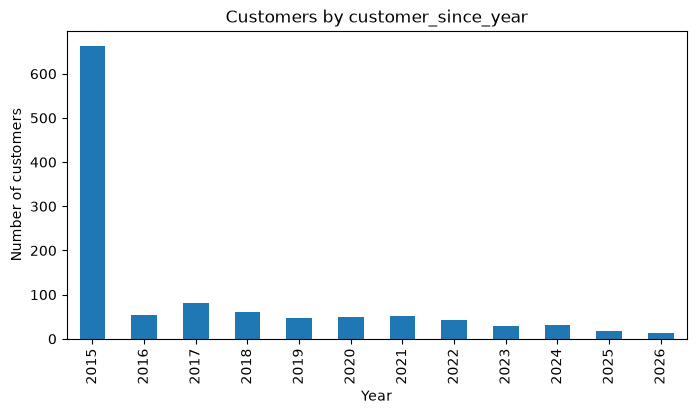

In [25]:
dist = pd.DataFrame({
    "n_customers": df["customer_since_year"].value_counts().sort_index(),
    "pct": (df["customer_since_year"].value_counts(normalize=True).sort_index() * 100).round(1)
})
dist
dist["n_customers"].plot(
    kind="bar",
    figsize=(8, 4),
    title="Customers by customer_since_year",
    xlabel="Year",
    ylabel="Number of customers"
);

In [26]:
# Skewness calculation (Assymetric)
skew_value = df['customer_since_year'].skew()
print(f"Skewness of customer_since_year: {skew_value:.2f}")

if skew_value > 0:
    print("Conclusion: Asymmetrical distribution to the right (right-skewed). Most customers joined long time ago, and the tail extends to the most recent years.")
elif skew_value < 0:
    print("Conclusion: Asymmetrical distribution to the left (left-skewed). Most customers joined in recent years.")
else:
    print("Conclusion: Approximately symmetric distribution.")

Skewness of customer_since_year: 1.36
Conclusion: Asymmetrical distribution to the right (right-skewed). Most customers joined long time ago, and the tail extends to the most recent years.


The mean (2017) is higher than the median (2015), so the distribution is right-skewed (skewness of 1.36), as the graphs show. This is not caused by outliers: 664 customers (58%) have `customer_since_year` = 2015, the minimum value, while the rest are spread over 2016–2026. Since 2015 is probably the year the records start, this value most likely groups all customers who joined in 2015 or earlier, which creates the peak on the left of the distribution.

Dominant category in 'country_or_region': Country CT10: Land of The Final Version with 94.4% of clients.


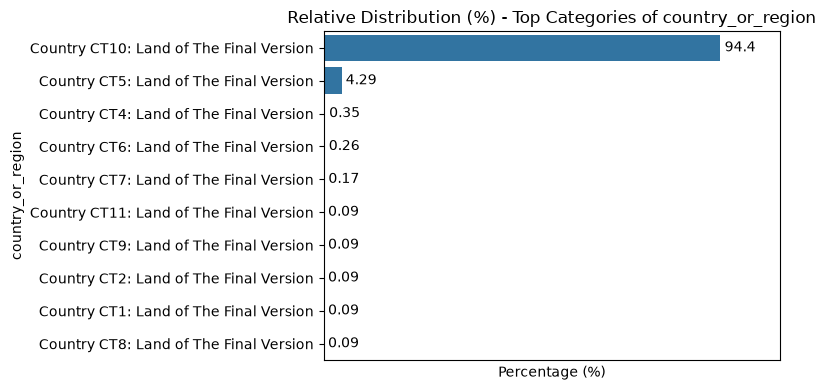

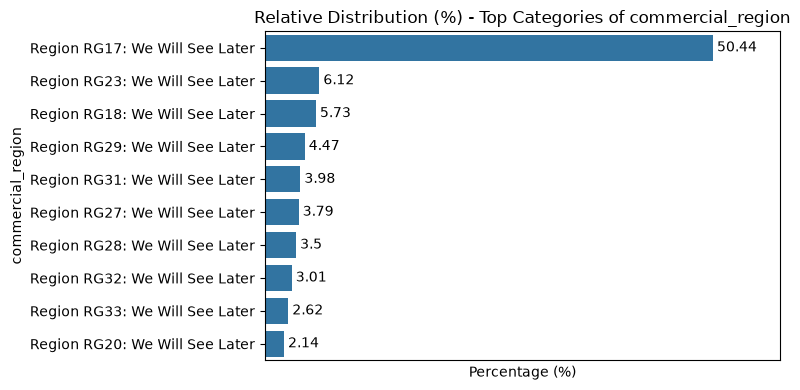

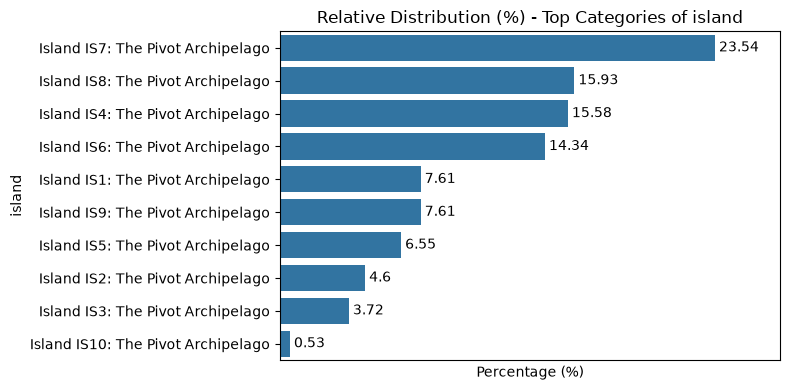

In [27]:
# Highlighting the inbalance of country_or_region(CT10)
country_counts = df['country_or_region'].value_counts(normalize=True) * 100
top_country = country_counts.index[0]
top_country_pct = country_counts.iloc[0]

print(f"Dominant category in 'country_or_region': {top_country} with {top_country_pct:.1f}% of clients.")

# Relative freq graph (%) for low cardinality
for col in ['country_or_region', 'commercial_region', 'island']:
    plt.figure(figsize=(8, 4))
    
    pcts = (df[col].value_counts(normalize=True).head(10) * 100).round(2)
    
    ax = sns.barplot(
        x=pcts.values,
        y=pcts.index,
        legend=False
    )
    
    # Add labels with the exact count at the end of each bar  
    for container in ax.containers:
        ax.bar_label(container, padding=3)
            
    #Remove the x-axis 
    plt.xticks([])
    plt.title(f"Relative Distribution (%) - Top Categories of {col}")
    plt.xlabel("Percentage (%)")
    plt.ylabel(col)
    plt.xlim(0, max(pcts.values) * 1.15)
    plt.tight_layout()
    plt.show()

• Total of unique categories: 183
• Categories with only one client: 65 (35.5% of total categories)


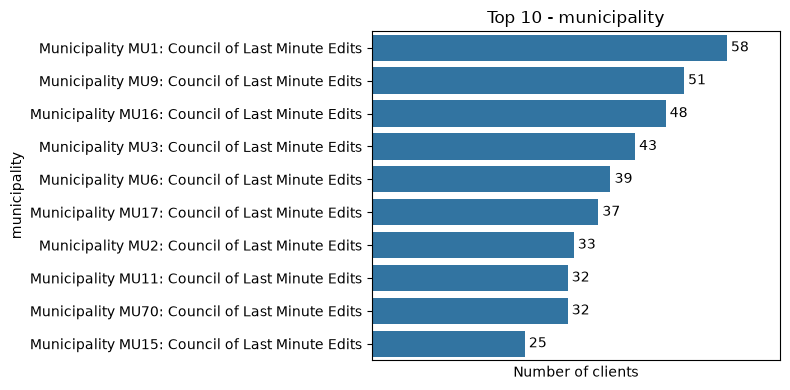

• Total of unique categories: 417
• Categories with only one client: 360 (86.3% of total categories)


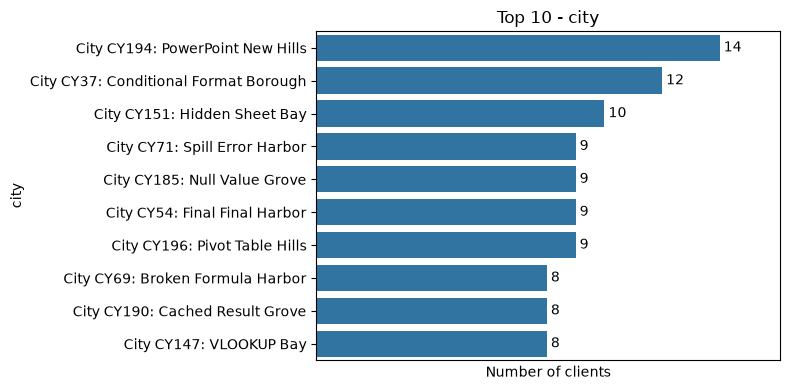

• Total of unique categories: 828
• Categories with only one client: 721 (87.1% of total categories)


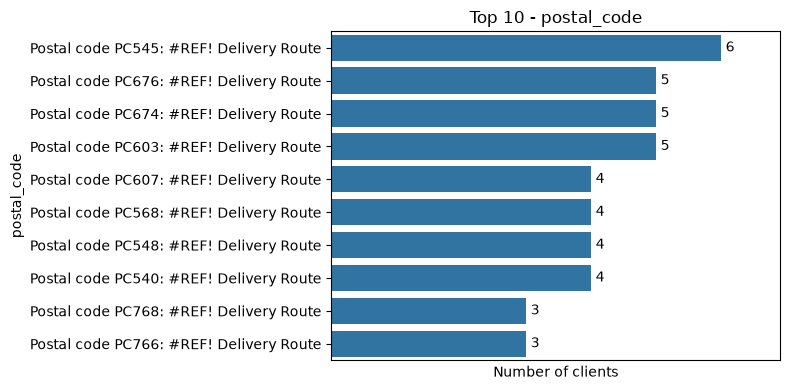

In [28]:
high_card_cols = ['municipality', 'city', 'postal_code']

for col in high_card_cols:
    if col in df.columns:
        counts = df[col].value_counts()
        total_categories = df[col].nunique()
        single_occurrence = (counts == 1).sum()
        pct_single = (single_occurrence / total_categories) * 100
        
        print(f"• Total of unique categories: {total_categories}")
        print(f"• Categories with only one client: {single_occurrence} ({pct_single:.1f}% of total categories)")
        
        # Graph only from the Top 10
        plt.figure(figsize=(8, 4))
        top10 = counts.head(10)
        
        ax = sns.barplot(
            x=top10.values,
            y=top10.index,
            legend=False
        )
        
        # Add labels with the exact count at the end of each bar  
        for container in ax.containers:
            ax.bar_label(container, padding=3)
        
        #Remove the X-axis 
        plt.xticks([])
        plt.title(f"Top 10 - {col}")
        plt.xlabel("Number of clients")
        plt.ylabel(col)
        plt.xlim(0, max(top10.values) * 1.15)
        plt.tight_layout()
        plt.show()

In [ ]:
# For Comercial Regions 
plt.figure(figsize=(10, 8))

# Filter only the regions with at least 1 client (> 0)
counts = df['commercial_region'].value_counts()
active_regions = counts[counts > 0].index

# Draw the graph
ax = sns.countplot(
    data=df,
    y='commercial_region',
    order=active_regions
)

# Add the label with the exact count at the end of each bar
ax.bar_label(ax.containers[0], padding=3)

# Adjusts the X-axis limit so the numbers don't get cut off at the margin  
plt.xlim(0, counts.max() * 1.1)

# Remove the X-axis count
plt.xticks([])

plt.title('Clients Distribution per Comercial Region')
plt.xlabel('Number of Clients')
plt.ylabel('Comercial Region')

plt.tight_layout()
plt.show()


---

 ### 1.7 Bivariate Analysis  

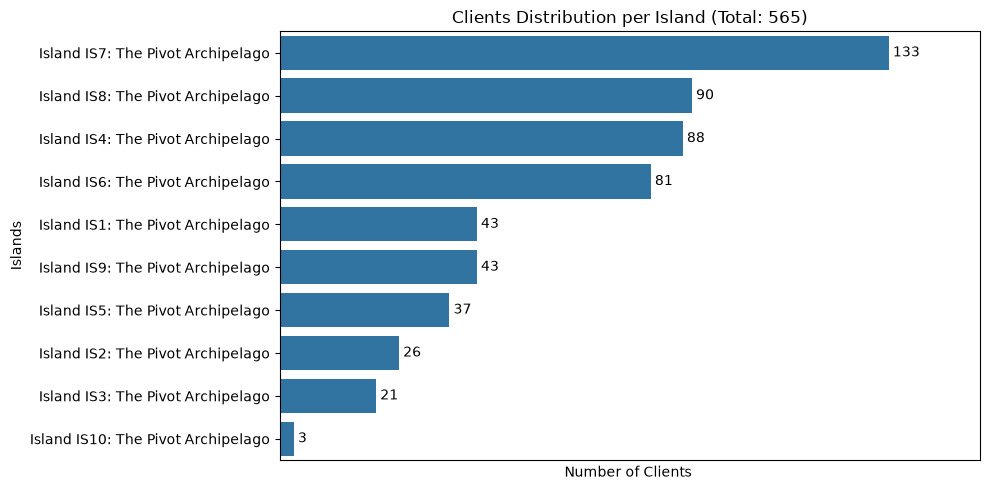

In [29]:
# For the islands(to analyse the 565 clients from the islands)
plt.figure(figsize=(10, 5))

# Filter only the islands with at least 1 client(> 0)
counts_island = df['island'].value_counts()
active_islands = counts_island[counts_island > 0].index

# Draw the horizontal bar chart (y='island')
ax = sns.countplot(
    data=df,
    y='island',
    order=active_islands
)

# Add labels with the exact count at the end of each bar  
ax.bar_label(ax.containers[0], padding=3)

# Adjust the limit of the X-axis  limit to leave space for the label numbers
plt.xlim(0, counts_island.max() * 1.15)

# Remove the number in the X-axis (below)
plt.xticks([])

plt.title("Clients Distribution per Island (Total: 565)")
plt.xlabel("Number of Clients ")
plt.ylabel("Islands")

plt.tight_layout()
plt.show()

In [30]:
from scipy.stats import chi2_contingency

# Hierarchy check: does each municipality belong to only one commercial region?
check_nesting = df.groupby("municipality")["commercial_region"].nunique()
print("Strictly nested (each municipality in exactly 1 commercial region):", check_nesting.max() == 1)

# Cramér's V (with bias correction) between two categorical variables
def cramers_v(x, y):
    cm = pd.crosstab(x, y)
    chi2 = chi2_contingency(cm)[0]
    n = cm.sum().sum()
    phi2 = chi2 / n
    r, k = cm.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    if min((kcorr-1), (rcorr-1)) <= 0:
        return 0.0
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

Strictly nested (each municipality in exactly 1 commercial region): True


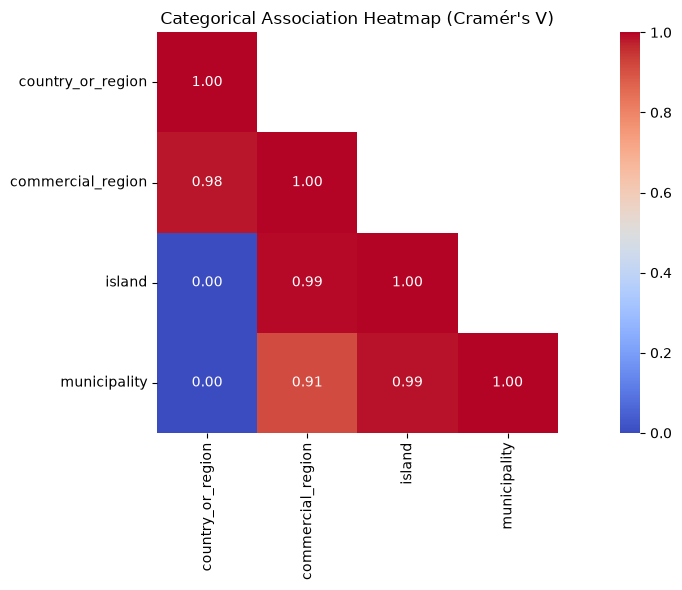

In [31]:
geo_cols = ['country_or_region', 'commercial_region', 'island', 'municipality']

matrix_v = pd.DataFrame(np.nan, index=geo_cols, columns=geo_cols)

for c in geo_cols:
    matrix_v.loc[c, c] = 1.0  # diagonal

# Lower triangle only: each pair is computed once (Cramér's V is symmetric)
for i, c1 in enumerate(geo_cols):
    for c2 in geo_cols[i + 1:]:
        pair = df[[c1, c2]].dropna()
        matrix_v.loc[c2, c1] = cramers_v(pair[c1], pair[c2])

plt.figure(figsize=(8, 6))
sns.heatmap(matrix_v, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=0, vmax=1, square=True,
            cbar_kws={'pad': 0.1})
plt.title("Categorical Association Heatmap (Cramér's V)")
plt.yticks(rotation=0)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 1.7.1 Geographic Hierarchy and Redundancy

The Cramér's V heatmap shows very strong associations among `commercial_region`, `island` and `municipality` (0.91 to 0.99). This is expected: the geographic variables are strictly nested, and the nesting check above confirms that each municipality belongs to exactly one commercial region. However, Cramér's V tends towards 1 when a variable has many categories (183 municipalities for about 1000 customers), so these values indicate redundancy but overstate its exact strength.

`country_or_region` is almost perfectly associated with `commercial_region` (0.98), but shows 0.00 with `island` and `municipality`. This is not a real absence of association: `island` and `municipality` are only filled for CT10 customers, so after removing the missing values only one country is left, and a variable with a single category always gives 0.

**Implication:** these features are largely redundant and would introduce severe categorical multicollinearity. We keep a single level of the hierarchy for predictive modelling.

In [32]:
df['country_or_region'].value_counts(normalize=True).head()


country_or_region
Country CT10: Land of The Final Version    0.944007
Country CT5: Land of The Final Version     0.042870
Country CT4: Land of The Final Version     0.003500
Country CT6: Land of The Final Version     0.002625
Country CT7: Land of The Final Version     0.001750
Name: proportion, dtype: float64

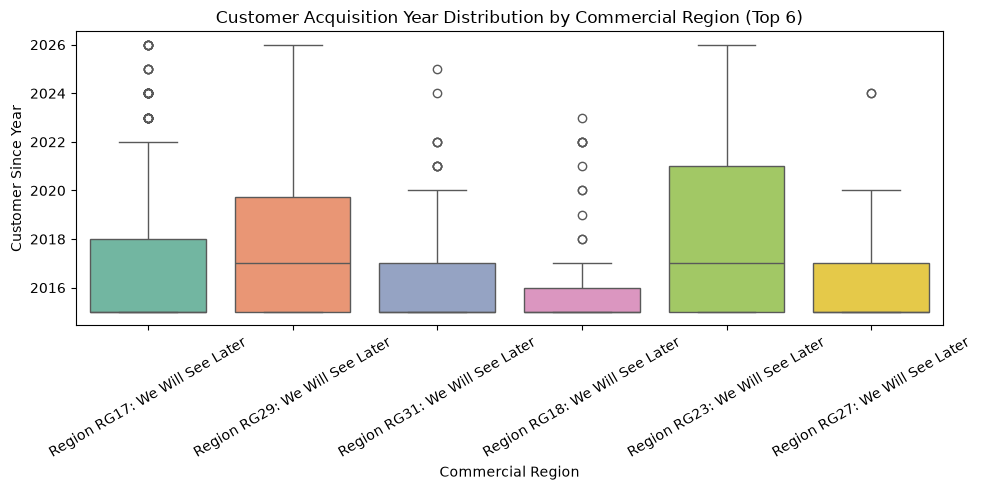

In [33]:
plt.figure(figsize=(10, 5))

# Select the top comercial regions for readability
top_reg = df['commercial_region'].value_counts().head(6).index
df_top_reg = df[df['commercial_region'].isin(top_reg)]

sns.boxplot(
    data=df_top_reg,
    x='commercial_region',
    y='customer_since_year',
    hue='commercial_region',
    palette='Set2',
    legend=False
)

plt.title("Customer Acquisition Year Distribution by Commercial Region (Top 6)")
plt.xlabel("Commercial Region")
plt.ylabel("Customer Since Year")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Temporal Distribution across Commercial Regions

Across the top six commercial regions, the median acquisition year is similar, between 2015 and 2017, so most regions share the same historical baseline. The differences are in the spread:

- **Concentrated, older base (RG18, RG31):** narrow interquartile range, with only a few recent customers appearing as outliers.
- **Wider spread, more recent acquisition (RG23, RG29):** the upper quartile and whiskers extend towards 2020–2026, so these regions kept acquiring customers for longer.
- **Mixed (RG17, RG27):** a compact core around 2015–2018, with some recent outliers.

Overall, regions differ less in *when* they started than in *how long* they kept growing.

---

### 1.8 Multivariate Analysis 

---

### Clients and Repeat Purchase

In [ ]:
TO DO!!!!